In [3]:
import netCDF4 as nc

# 读取文件
file_u = nc.Dataset('G:\Meteorological\ZZ/10m_u_component_of_wind_stream-oper_daily-mean.nc')
file_v = nc.Dataset('G:\Meteorological\ZZ/10m_v_component_of_wind_0_daily-mean.nc')

# 打印文件结构
print("U文件变量：", file_u.variables.keys())
print("V文件变量：", file_v.variables.keys())

# 查看经纬度和时间维度（假设为标准命名）
print("U文件维度：", file_u.dimensions)
# print("时间变量：", file_u.variables['time'][:])  # 时间戳可能需要转换

U文件变量： dict_keys(['latitude', 'longitude', 'valid_time', 'u10', 'number'])
V文件变量： dict_keys(['latitude', 'longitude', 'valid_time', 'v10', 'number'])
U文件维度： {'latitude': "<class 'netCDF4.Dimension'>": name = 'latitude', size = 117, 'longitude': "<class 'netCDF4.Dimension'>": name = 'longitude', size = 141, 'valid_time': "<class 'netCDF4.Dimension'>": name = 'valid_time', size = 6}


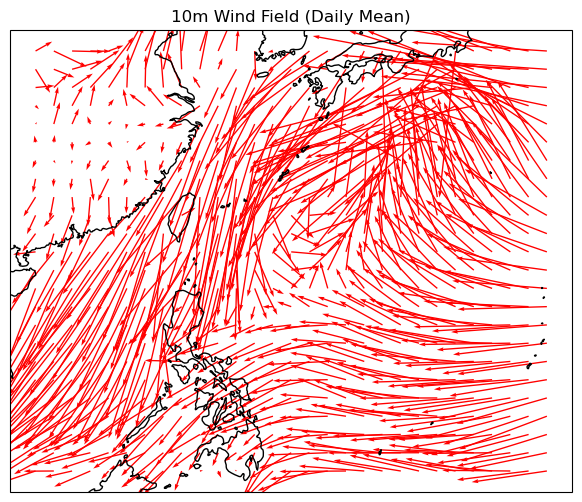

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# 提取数据（假设变量名为'u10'和'v10'）
u = file_u.variables['u10'][:]  # 时间层可选，如[0]表示第一个时间点
v = file_v.variables['v10'][:]
lat = file_u.variables['latitude'][:]
lon = file_u.variables['longitude'][:]

# 创建地图
fig = plt.figure(figsize=(10, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()

# 绘制风场箭头（每隔5个点采样避免拥挤）
skip = 5
ax.quiver(lon[::skip], lat[::skip], u[0, ::skip, ::skip], v[0, ::skip, ::skip], 
          transform=ccrs.PlateCarree(), scale=50, color='red')

plt.title('10m Wind Field (Daily Mean)')
plt.show()

In [15]:
u = file_u.variables['u10'][:]
v = file_v.variables['v10'][:]
u.shape
v.shape

(6, 117, 141)

C:\Users\minyu\AppData\Local\Temp\ipykernel_37120\2132832138.py:1: FutureWarning: icepyx v1.x is being deprecated; the back-end systems on which it relies
will be shut down as of late 2024. At that time, upgrade to icepyx v2.x, which uses the
new NASA Harmony back-end, will be required. Please see
<https://icepyx.readthedocs.io/en/latest/user_guide/changelog/v1.3.0.html> for more
information!

  import icepyx as ipx
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
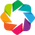

In [1]:

import icepyx as ipx
import numpy as np
import xarray as xr
import pandas as pd
import h5py
import os, json
from pprint import pprint
import dask.dataframe as dd
import rioxarray as rxr
import rasterio
import rasterio
from pyproj import Transformer
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam, read_hdf5_atl03_coordinate

In [2]:
import glob
import re
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator


from readers.add_atl08_info import add_atl08_classed_flag
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam_h5py

def read_hdf5_atl03_beam_h5py(filename, beam, verbose=False):
    """
    ATL03 原始数据读取
    Args:
        filename (str): h5文件路径
        beam (str): 光束
        verbose (bool): 输出HDF5信息

    Returns:
        返回ATL03光子数据的heights和geolocation信息
    """

    # 打开HDF5文件进行读取
    file_id = h5py.File(os.path.expanduser(filename), 'r')

    # 输出HDF5文件信息
    if verbose:
        print(file_id.filename)
        print(list(file_id.keys()))
        print(list(file_id['METADATA'].keys()))

    # 为ICESat-2 ATL03变量和属性分配python字典
    atl03_mds = {}

    # 读取文件中每个输入光束
    beams = [k for k in file_id.keys() if bool(re.match('gt\\d[lr]', k))]
    if beam not in beams:
        print('请填入正确的光束代码')
        return

    atl03_mds['heights'] = {}
    atl03_mds['geolocation'] = {}
    atl03_mds['bckgrd_atlas'] = {}

    # -- 获取每个HDF5变量
    # -- ICESat-2 Measurement Group
    for key, val in file_id[beam]['heights'].items():
        atl03_mds['heights'][key] = val[:]

    # -- ICESat-2 Geolocation Group
    for key, val in file_id[beam]['geolocation'].items():
        atl03_mds['geolocation'][key] = val[:]

    for key, val in file_id[beam]['bckgrd_atlas'].items():
        atl03_mds['bckgrd_atlas'][key] = val[:]

    return atl03_mds

def get_atl03_x_atc(atl03_mds):
    val = atl03_mds

    # 初始化
    val['heights']['x_atc'] = np.zeros_like(val['heights']['h_ph']) + np.nan
    val['heights']['y_atc'] = np.zeros_like(val['heights']['h_ph']) + np.nan
    val['geolocation']['ref_elev_all'] = np.zeros_like(val['heights']['h_ph'])

    # -- ATL03 Segment ID
    segment_id = val['geolocation']['segment_id']
    # -- 分段中的第一个光子（转换为基于0的索引）
    segment_index_begin = val['geolocation']['ph_index_beg'] - 1
    # -- 分段中的光子事件数
    segment_pe_count = val['geolocation']['segment_ph_cnt']
    # -- 每个ATL03段的沿轨道距离
    segment_distance = val['geolocation']['segment_dist_x']
    # -- 每个ATL03段的轨道长度
    segment_length = val['geolocation']['segment_length']

    # -- 对ATL03段进行迭代，以计算40m的平均值
    # -- 在ATL03中基于1的索引：无效==0
    # -- 此处为基于0的索引：无效==-1
    segment_indices, = np.nonzero((segment_index_begin[:-1] >= 0) &
                                  (segment_index_begin[1:] >= 0))
    for j in segment_indices:
        # -- j 段索引
        idx = segment_index_begin[j]
        # -- 分段中的光子数（使用2个ATL03分段）
        c1 = np.copy(segment_pe_count[j])
        c2 = np.copy(segment_pe_count[j + 1])
        cnt = c1 + c2

        # -- 沿轨道和跨轨道距离
        # -- 获取当前段光子列表，idx当前段(j)第一个光子数量，c1当前段光子数量，idx+c1当前段长度
        distance_along_x = np.copy(val['heights']['dist_ph_along'][idx: idx + cnt])
        ref_elev = np.copy(val['geolocation']['ref_elev'][j])
        # -- 给当前段的光子加上当前段沿轨道距离
        distance_along_x[:c1] += segment_distance[j]
        distance_along_x[c1:] += segment_distance[j + 1]
        distance_along_y = np.copy(val['heights']['dist_ph_across'][idx: idx + cnt])

        val['heights']['x_atc'][idx: idx + cnt] = distance_along_x
        val['heights']['y_atc'][idx: idx + cnt] = distance_along_y
        val['geolocation']['ref_elev_all'][idx: idx + c1] += ref_elev

def read_data(filepath, beam, mask_lat, mask_lon):
    """
    读取数据，返回沿轨道距离和高程距离
    :param filepath: h5文件路径
    :param beam: 轨道光束
    :param mask_lat: 维度范围
    :param mask_lon: 经度范围
    :return:
    """
    atl03_file = glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_beam(atl03_file[0], beam=beam, verbose=False)
    # 添加沿轨道距离到数据中
    get_atl03_x_atc(is2_atl03_mds)
    # 选择范围
    d3 = is2_atl03_mds
    subset1 = (d3['heights']['lat_ph'] >= min(mask_lat)) & (d3['heights']['lat_ph'] <= max(mask_lat))
    print(subset1.shape, 'sss')
    zz = d3['heights']['h_ph']
    print(zz.shape, 'zz')
    if mask_lon is not None:
        if mask_lon[0] is not None and mask_lon[1] is None:
            subset1 = subset1 & (d3['heights']['x_atc'] >= mask_lon[0])
        elif mask_lon[0] is None and mask_lon[1] is not None:
            subset1 = subset1 & (d3['heights']['x_atc'] <= mask_lon[1])
        else:
            subset1 = subset1 & (d3['heights']['x_atc'] >= min(mask_lon)) & (d3['heights']['x_atc'] <= max(mask_lon))
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    ref_elev = d3['geolocation']['ref_elev_all'][subset1]
    print(d3['heights'])
    print(d3.keys())
    print(d3['heights'].keys(), 'height')
    print(d3['geolocation'].keys(), 'location key')
    print(d3['bckgrd_atlas'].keys(), 'bckgrd_atlas')
    print(d3['heights']['quality_ph'], 'quality_ph')
    del d3, subset1
    return x_act, h, signal_conf_ph, lat, lon, ref_elev

def read_all_beam_coordinate(filepath, mask_lat, mask_lon):
    """
    读取所有波束的数据
    :param filepath:
    :param mask_lat:
    :param mask_lon:
    :return:
    """
    atl03_file = glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_coordinate(atl03_file[0])

    # 禁止加载全部数据
    # if mask_lat is None or len(mask_lat) == 0 or mask_lon is None or len(mask_lon) == 0:
    #     return False

    d3 = is2_atl03_mds
    if mask_lon is None and mask_lat is None:
        # 加载全部数据
        return d3
    for beam in is2_atl03_mds.keys():
        subset1 = (d3[beam]['lat'] >= min(mask_lat)) & (d3[beam]['lat'] <= max(mask_lat))
        subset1 = subset1 & (d3[beam]['lon'] >= min(mask_lon)) & (d3[beam]['lon'] <= max(mask_lon))
        d3[beam]['lat'] = d3[beam]['lat'][subset1]
        d3[beam]['lon'] = d3[beam]['lon'][subset1]
    return d3

def read_hdf5_atl08(filename, beam, verbose=False):
    file_id = h5py.File(os.path.expanduser(filename), 'r')

    # 输出HDF5文件信息
    if verbose:
        print(file_id.filename)
        print(list(file_id.keys()))
        print(list(file_id['METADATA'].keys()))
    # 为ICESat-2 ATL08变量和属性分配python字典
    atl08_mds = {}

    # 读取文件中每个输入光束
    beams = [k for k in file_id.keys() if bool(re.match('gt\\d[lr]', k))]
    if beam not in beams:
        print('请填入正确的光束代码')
        return
    # atl08_land_segement = {}
    # for key, val in file_id[beam]['land_segments'].items():
    #     atl08_land_segement['land_segments'][key] = val[:]
    atl08_mds['land_segments'] = {}
    atl08_mds['signal_photons'] = {}
    print(atl08_mds)
    # -- ICESat-2 Geolocation Group
    for key, val in file_id[beam]['signal_photons'].items():
        print(val)
        atl08_mds['signal_photons'][key] = val[:]

    return atl08_mds

def select_atl03_data(atl03_data, mask, TF_height_range):
    """
    选择数据范围
    Args:
        atl03_data: 所有数据
        mask (list): 维度范围
    Returns:
    """
    # 选择范围
    d3 = atl03_data
    subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    #subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    classed_pc_flag = d3['classed_pc_flag'][subset1]

    return x_act, h, signal_conf_ph, lat, lon, classed_pc_flag

def select_atl03_data2(atl03_data, mask, TF_height_range):
    """
    选择数据范围
    Args:
        atl03_data: 所有数据
        mask (list): 维度范围
    Returns:
    """
    # 选择范围
    d3 = atl03_data
    #subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    classed_pc_flag = d3['classed_pc_flag'][subset1]

    return x_act, h, signal_conf_ph, lat, lon, classed_pc_flag

def select_atl03_data3(atl03_data, mask, TF_height_range):
    """
    选择数据范围
    Args:
        atl03_data: 所有数据
        mask (list): 维度范围
    Returns:
    """
    # 选择范围
    d3 = atl03_data
    #subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    #subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) #& (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 
    
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    classed_pc_flag = d3['classed_pc_flag'][subset1]

    return x_act, h, signal_conf_ph, lat, lon, classed_pc_flag

def get_atl03_data(filepath, beam):
    """
    读取ATL03数据，根据维度截取数据
    Args:
        filepath (str): h5文件路径
        beam (str): 光束
    Returns:
        返回沿轨道距离，高程距离，光子置信度
    """
    atl03_file = glob.glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_beam_h5py(atl03_file[0], beam=beam, verbose=False)
    # 添加沿轨道距离到数据中
    get_atl03_x_atc(is2_atl03_mds)
    return is2_atl03_mds
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam, read_hdf5_atl03_coordinate

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re

def get_atl_group(folder_path_03, folder_path_08):

    alt03_file_list = glob.glob(os.path.join(folder_path_03, '*ATL03*.h5'))
    n = len(alt03_file_list)

    ATL_name_group = []
    for i in range(n):
        
        # find keyword (date and orbit number)
        file_path = alt03_file_list[i]
        time_match = re.search(r'ATL03_(\d{14})_', file_path)
        orbit_match = re.search(r'ATL03_\d{14}_(\d{8})_', file_path)
        Imaging_date = time_match.group(1)[:8]
        orbit_num = orbit_match.group(1)

        # search target ATL03/08 file with the same keyword (data)
        alt03_file_list_ = glob.glob(os.path.join(folder_path_03, f'*ATL03*{Imaging_date}*{orbit_num}*.h5'))
        alt08_file_list = glob.glob(os.path.join(folder_path_08, f'*ATL08*{Imaging_date}*{orbit_num}*.h5'))
        
        # Construct ATL_pair and storage in ATL_name_group( 2-D List)
        if (len(alt08_file_list) == 1) & (len(alt08_file_list) == 1):
            ATL_pair = [alt03_file_list_[0], alt08_file_list[0]]
            ATL_name_group.append(ATL_pair)

    return ATL_name_group

def find_anomaly(indices_list):
    b = []
    if len(indices_list) <= 5:
        value = 100
    else:
        for i in range(1,len(indices_list)):
            b.append(indices_list[i] - indices_list[i-1])
            
        if max(b) > 5:
            index_max = [index for index, value in enumerate(b) if value == max(b)]
            value = indices_list[index_max[0]+1]
        else:
            value = indices_list[0]
        
    return value

def sea_height_cal(input, height_name, derivative_thred):
    
    if  isinstance(input, str):
        data = pd.read_csv(input)
        df = pd.DataFrame(data)
    else:
        df = input
    
    percentile, derivative, derivative_2th = [], [0], [0]
    height_TS = pd.DataFrame()
    
    if len(df) < 100:
        return 0, height_TS
    else:
        
        for i in range(0, 101):
            p = np.percentile(df[height_name], i)
            percentile.append(p)

        height_TS['percentile'] = percentile
        
        height_TS['percentile'][:5] = height_TS['percentile'][5]
        
        short_window, long_window = 5, 10
        height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']

        indices = [index for index, value in enumerate(height_TS['MACD']) if value > derivative_thred]
        target_index = find_anomaly(indices)
        # if indices == []:
        #     indices = [100]

        print(indices[:10], 'indices')
        print(target_index, 'target_index')
        # sea_height = percentile[target_index]
        sea_height = percentile[target_index]
        
        return  sea_height, df#, height_TS, target_index
    
def sea_height_cal_for_view(input, height_name, derivative_thred):
    
    if  isinstance(input, str):
        data = pd.read_csv(input)
        df = pd.DataFrame(data)
    else:
        df = input
    
    percentile, derivative, derivative_2th = [], [0], [0]
    height_TS = pd.DataFrame()
    
    if len(df) < 100:
        return 0, height_TS
    else:
        
        for i in range(0, 101):
            p = np.percentile(df[height_name], i)
            percentile.append(p)

        height_TS['percentile'] = percentile
        short_window, long_window = 5, 10
        # height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        # height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        # height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']
        
        height_TS['percentile'][:5] = height_TS['percentile'][5]

    #----------------------------------------------------------------
        height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']
        # height_TS['MACD'] = height_TS['Z'].ewm(span=5, adjust=False).mean()
        # height_TS['DEA'] =  height_TS['DIF'].ewm(span=25, adjust=False).mean()
        # height_TS['MACD'] = height_TS['DIF'] - height_TS['DEA']
    
    #----------------------------------------------------------------
    
        indices = [index for index, value in enumerate(height_TS['MACD']) if value > derivative_thred]
        target_index = find_anomaly(indices)
        # if indices == []:
        #     indices = [100]

        print(indices[:10], 'indices')
        print(target_index, 'target_index')
        #sea_height = percentile[target_index]
        sea_height = percentile[target_index]
        return  sea_height, df , height_TS, target_index
    
def icesat_gt_processing(alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance, sea_thred, is_display = True):
    
    sea_height_list = []
    df_list = []
    df_sea_point_remove_list = []
    
    # calculate each beams
    for i in range(len(beam)):
    
        atl03_data = get_atl03_data(alt03_path, beam[i])
        add_atl08_classed_flag(alt08_path, beam[i], atl03_data)
        x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data(atl03_data, region_mask, TF_height_range)
        z = pd.DataFrame()
        z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
        z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
        re_accumulate =  z.groupby('distance').agg(
            
            mean_height = ('height', 'mean'),
            mean_lon = ('longtitude', 'mean'),
            mean_lat = ('latitude', 'mean')
        ).reset_index()

        if re_accumulate.empty | len(re_accumulate) < 200:
            continue

        sea_height, df, height_TS, target_index = sea_height_cal_for_view(re_accumulate, 'mean_height', sea_thred)  
        if sea_height > 0:
            sea_height_list.append(sea_height)
            df_list.append(df)    
    
    if sea_height_list == []:
        empty = pd.DataFrame()
        return empty, [], [], []

#--------------------------------------------------------------------------------------------------------------  
    log = []
    log.append('sea height list:' + str(sea_height_list) + ' --- ')

    # calculate Final_sea_height
    
    print(sea_height_list, 'sea_height_list')
    if np.max(sea_height_list) - np.min(sea_height_list) > 1:
        sort_ = np.sort(sea_height_list)
        print('sorted', sort_, type(sort_))
        _ = []
        for i in range(len(sea_height_list)-1):
            _.append(sort_[i+1] - sort_[i])

        index_max = [index for index, value in enumerate(_ ) if value == max(_)]

        if (index_max[0]+1) <= len(sort_)/2:
            index_max = len(sort_)-1
        
        Final_sea_height = sort_[index_max].item()
    else:
        Final_sea_height = np.max(sea_height_list)

    print(Final_sea_height,'Final_sea_height', type(Final_sea_height))
    log.append('Final_sea_height :'+ str(Final_sea_height) + '\n')
    
#---------------------------------------------------------------------------------------------------------------
    
    # Apply Final_sea_height for all beams
    for j in range(len(df_list)):
        mask = df_list[j]['mean_height'] > Final_sea_height
        print(type(mask), 'type mask', len(mask), 'mask len')
        
        df_sea_point_remove = df_list[j][mask]
        
        if df_sea_point_remove.empty:
            print(filepath_03 + '_' + beam[j] + ' is empty')
        
        df_sea_point_remove_list.append(df_sea_point_remove)
        
        df_list[j]['sea_height'] = Final_sea_height
        df_list[j]['sea_point'] =  df_list[j]['mean_height'] <= Final_sea_height
        
        if is_display:
           
            plt.figure(figsize=(10, 3))
            plt.plot(df_list[j]['mean_height'], color ='gray',label = 'height')
            plt.plot(df_list[j]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
            plt.scatter(df_list[j].index[df_list[j]['sea_point']], df_list[j]['mean_height'][df_list[j]['sea_point']], color = 'red', label = 'sea points', zorder = 0.5)
            plt.legend()
            plt.ylabel('height')
            plt.xlabel('photons')
            plt.show()
            
            fig, ax1 = plt.subplots(figsize=(10,3))
            _ = np.arange(0, 101)
            ax1.plot(_, height_TS['percentile'], label = 'percentile', color = 'black')
            ax1.set_xlabel('X-axis')
            ax1.set_ylabel('Height(m)', color = 'black')
            ax1.tick_params(axis='y', labelcolor='black')
           # ax1.axhline(df_list[j]['sea_height'][0], color = 'red', linestyle = '--')
            ax1.legend()
            
            ax2 = ax1.twinx()
            ax2.plot(_, height_TS['MACD'], 'r--', label = 'MACD', color = 'blue')
           # ax2.plot(_, height_TS['Signal'], 'r--', label = 'Signal', color = 'green')
            ax2.set_ylabel('MACD', color = 'blue')

            ax2.tick_params(axis = 'y', labelcolor = 'blue')
            ax2.axhline(0, color = 'gray', linestyle = '--')
            ax2.axvline(target_index, color = 'red', linestyle = '--', label = 'Threshold')
            ax2.legend()
            
            plt.show()

            #-------------------------------------
    
    merged_df = pd.concat(df_sea_point_remove_list, ignore_index=True)
    
    return merged_df, sea_height_list, Final_sea_height, log

In [4]:
def icesat_gt_processing3_new_for_raw(No ,alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance):
    
    
    osgm_path = 'G:\OSGM15\Great_Britain_osgm15.tif'
    df_sea_point_remove_list = []
    local_strip_height_list = []
    ICESat_2_point_list = []
    log = []
    
    for i in range(len(beam)):
        
        df_list = []
        sea_height_list = []
        
        for j in range(len(beam[i])):
            
            atl03_data = get_atl03_data(alt03_path, beam[i][j])
            add_atl08_classed_flag(alt08_path, beam[i][j], atl03_data)
            x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data3(atl03_data, region_mask, TF_height_range)
            x_origin1, y_origin1, _, lat1, _, _ = select_atl03_data2(atl03_data, region_mask, TF_height_range)
            z = pd.DataFrame()
            z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
            z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
            re_accumulate =  z.groupby('distance').agg(
                
                mean_height = ('height', 'mean'),
                mean_lon = ('longtitude', 'mean'),
                mean_lat = ('latitude', 'mean')
            ).reset_index()
            
            if re_accumulate.empty | len(re_accumulate) < 10:
                print('photon less than 200!')
                continue
        
            ICESat_2_point_list.append(re_accumulate)
    
    if ICESat_2_point_list == []:
        merged_df = pd.DataFrame()
        return merged_df
        
    merged_df = pd.concat(ICESat_2_point_list, ignore_index=True)
    return merged_df
    

In [5]:
if __name__ == '__main__':
    
    REGION = 'Region5'
    #----------------------------------------------------------------------------------------
    #--------------------------------------Region 2 -----------------------------------------
    year_list = [2019, 2020, 2021, 2022, 2023]
    year_list = [2022]
    # Region_info = {
    #         'region1': {'name':'wash_bay', 'mask':[[0.041, 0.807], [52.756, 53.163]]},
    #         'region2': {'name':'Henber'  , 'mask':[[-0.839, 0.382], [53.164, 53.852]]},
    #         'region3': {'name':'Region2a', 'mask':[[-0.906, -0.060], [53.852, 54.443]]}
    #     } 
    Region_info = {

            'region1': {'name':'Region5a', 'mask':[[-11.3587,2.5279], [49.7857, 59.6268]]},
        } 

    detect_region = 'region1'

    print('region:' ,Region_info[detect_region]['name'])
    print('region_mask:', Region_info[detect_region]['mask'])

    region_name = Region_info[detect_region]['name']
    mask = Region_info[detect_region]['mask']
    TF_height_range = [30, 70]
    #----------------------------------------------------------------------------------------
    for j in range(len(year_list)):

        year = year_list[j]

        output_root_path = f'G:\ICESat-2\{REGION}\{REGION}_{region_name}'
        if not os.path.exists(output_root_path):
            os.makedirs(output_root_path)
            output_path = f'G:\ICESat-2\{REGION}\{REGION}_{region_name}\A_{region_name}_30m_{year}_new10_for_all_raw.csv'
        else:
            output_path = f'G:\ICESat-2\{REGION}\{REGION}_{region_name}\A_{region_name}_30m_{year}_new10_for_all_raw.csv'

        log_path =  f'G:\ICESat-2\{REGION}\{REGION}_{region_name}\A_log_{region_name}_{year}_new10.txt'
        

        folder_path_03  = f'G:\ICESat-2\{REGION}\{REGION}_{year}\ATL03_{REGION}_{year}'
        folder_path_08 =  f'G:\ICESat-2\{REGION}\{REGION}_{year}\ATL08_{REGION}_{year}' 
        #beam = ['gt1l', 'gt2l', 'gt3l', 'gt1r', 'gt2r', 'gt3r']
        beam = [['gt1l', 'gt1r'], ['gt2l', 'gt2r'] ,['gt3l', 'gt3r']]
        ATL_name_group = get_atl_group(folder_path_03, folder_path_08)
        
        output = []
        log_list = []
        
        for i in range(len(ATL_name_group)):
        #for i in range(0,3):
        # for i in range(20, 21):
            
            filepath_03 = ATL_name_group[i][0]
            filepath_08 = ATL_name_group[i][1]
            
            merged_df = icesat_gt_processing3_new_for_raw(i, filepath_03, filepath_08, beam, mask, TF_height_range,  3000)
            
            if merged_df.empty:
                continue
            
            print('------------------------------------')
            output.append(merged_df)
            print('No_'+str(i) + '_' + str(filepath_03) + ' is done')
            print(str(round(i*100/len(ATL_name_group), 2))+ '%' + ' is done')
            # log.append('No_'+str(i) + ': ' + str(filepath_03) + '\n')
            # log_list.append(log)
         #-----------------------------output log info-------------------------------------- 
        
        # with open(log_path, "w") as file:
        #     for logs in log_list:
        #         for log in logs:
        #             file.write(log)
        #-------------------------- output result-------------------------------------------
              
        output = pd.concat(output, ignore_index=True) 
        print('output_len: ',len(output))
        print(output[:10])
        # output.to_csv(output_path)

region: Region5a
region_mask: [[-11.3587, 2.5279], [49.7857, 59.6268]]
------------------------------------
No_0_G:\ICESat-2\Region5\Region5_2022\ATL03_Region5_2022\ATL03_20220101195541_01611406_006_01.h5 is done
0.0% is done
------------------------------------
No_1_G:\ICESat-2\Region5\Region5_2022\ATL03_Region5_2022\ATL03_20220105194719_02221406_006_01.h5 is done
1.09% is done
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
------------------------------------
No_2_G:\ICESat-2\Region5\Region5_2022\ATL03_Region5_2022\ATL03_20220108070553_02601402_006_01.h5 is done
2.17% is done
------------------------------------
No_3_G:\ICESat-2\Region5\Region5_2022\ATL03_Region5_2022\ATL03_20220109193903_02831406_006_01.h5 is done
3.26% is done
------------------------------------
No_4_G:\ICESat-2\Region5\Region5_2022\ATL03_Region5_2022\ATL03_20220112065734_03211402_006_01.h5 is done
4.35% is done
------------------------------------
No_

In [6]:
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd

output_path = f'G:\ICESat-2\ICESAT_2022_raw/A_{REGION}_30m_{year}_new10_for_all_raw.shp'

geometry = [Point(xy) for xy in zip(output['mean_lon'], output['mean_lat'])]
gdf = gpd.GeoDataFrame(output, geometry=geometry, crs='EPSG:4326')

gdf.to_file(output_path)